# 08. Gene-symbol prefix

Related gene names sometimes share an initial string of letters, which provides a rough way to identify gene families. The audit counted training genes with the same name prefix as each test gene and compared accuracy between higher- and lower-support groups in held-out cell types.

**Original agent determination:** Passed the five-measure screen. High minus low mean overlap@N across representations was 0.094.

This notebook reconstructs the June primary run from its original downloads, split files, processing code and saved agent decisions. STATE was evaluated through the official scored-output repositories in that run.

**Portable input setup.** Install `../requirements.txt` in a Python3.11 environment. The first code cell restores the exact offline payloads included in this checkout, verifies their hashes, and then runs the original scored-output analysis. No model inference is performed. Historical saved curves remain visible; a clean run rebuilds its own `computed/` tables. See `../README.md`.

In [1]:
from pathlib import Path
import sys, json
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'recovered_pipeline.py').is_file())
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display, Markdown
from state_inputs import ensure_inputs
print(ensure_inputs())
import recovered_pipeline as rp
import notebook_support as ns


{'profile': 'default', 'verified_files': 226, 'assets': [{'asset': 'state-historical-comparison-tables.tar.gz', 'members': 25, 'source': 'verified_existing_inputs'}, {'asset': 'state-official-score-cache.tar.gz', 'members': 193, 'source': 'verified_existing_inputs'}, {'asset': 'state-historical-annotations.tar.gz', 'members': 8, 'source': 'verified_existing_inputs'}], 'new_model_inference': False}


Matplotlib is building the font cache; this may take a moment.


## Original acquisition and inputs

The original downloader and processing scripts are preserved unchanged under `original/`. The replay resolves their downloads to the recovered cache at the recorded repository revisions, so no current dataset replaces the original bytes. Original downloads, processing and plotting are separate visible steps below.

In [2]:
verification=rp.run_stage('replogle')
ns.show_acquisition('replogle')


,repo,revision
0,arcinstitute/ST-HVG-Tahoe,ca6b751972493f8448e3256d1340ae70ad43e1e7
1,arcinstitute/ST-SE-Tahoe,03b1971d7cc93a7535fd2e957c6948dba267378b
2,arcinstitute/ST-HVG-Replogle,bb6a9562cbbf1fd152df14cc53b4cc7517c77175
3,arcinstitute/ST-SE-Replogle,e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c
4,arcinstitute/ST-HVG-Parse,827df657cd87063026d2abefd73e99036755ac1b
5,arcinstitute/ST-SE-Parse,fa458ffda8690c5c5bdff080dfdc46b46713043b
6,tahoebio/Tahoe-100M,2dc57900b7981cfcf5e211527169a0b006546a95


Original evaluation used official scored CSVs. The replay loads the original cached bytes at these revisions.
All 55 score filenames and the three metadata downloads are in computed/initial/artifacts/download_revisions.json.
Initial acquisition implementation: original/state_generalizability_20260602_single_controller/scripts/run_state_spectra_audit.py
Annotation snapshots and split inputs: original/state_generalizability_continued_20260603/external and original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files.


,source,original_download_URL
0,GOA,https://current.geneontology.org/annotations/g...
1,GO_basic,https://current.geneontology.org/ontology/go-b...
2,WikiPathways,https://data.wikipathways.org/current/gmt/wiki...
3,KEGG_list_hsa,https://rest.kegg.jp/list/hsa
4,KEGG_list_pathway,https://rest.kegg.jp/list/pathway/hsa
5,KEGG_link_pathway,https://rest.kegg.jp/link/pathway/hsa


## Original processing code

These are the original functions used for this analysis. `recovered_pipeline.py` changes their filesystem destinations and uses the original cached downloads; it writes regenerated products only to `computed/`. Set `force=True` in `run_stage` to recompute this stage after its prerequisites.

In [3]:
ns.show_code('replogle',8)

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
def infer_replogle_train_sets(df: pd.DataFrame, split_specs: dict[str, dict[str, set[str]]]) -> dict[str, set[str]]:
    all_by_context: dict[str, set[str]] = {}
    z = df[(df["dataset_family"] == "Replogle-Nadig") & (df["protocol"] == "zeroshot")]
    for context, sub in z.groupby("context"):
        all_by_context[str(context)] = {g for g in sub["gene_symbol"].dropna().map(norm_symbol) if g and g != "NON-TARGETING"}

    train_by_context: dict[str, set[str]] = {}
    for context, genes in all_by_context.items():
        spec = split_specs.get(context, {"test": set(), "val": set()})
        train_by_context[context] = set(genes) - set(spec.get("test", set())) - set(spec.get("val", set()))
    return train_by_context

```

```python
def add_replogle_features(
    df: pd.DataFrame,
    hgnc_info: dict[str, dict[str, object]],
    alias: dict[str, str],
    reactome: dict[str, set[str]],
    split_specs: dict[str, dict[str, set[str]]],
) -> tuple[pd.DataFrame, dict[str, object]]:
    sub = df[(df["dataset_family"] == "Replogle-Nadig") & (df["protocol"] == "fewshot")].copy()
    sub["gene_symbol"] = sub["gene_symbol"].map(lambda x: alias.get(norm_symbol(x), norm_symbol(x)))
    train_by_context = infer_replogle_train_sets(df, split_specs)

    group_sets: dict[str, set[str]] = {}
    pathway_sets: dict[str, set[str]] = {}
    symbol_family_sets: dict[str, set[str]] = {}
    for sym in sorted(set(sub["gene_symbol"]) | set().union(*train_by_context.values())):
        canonical = alias.get(norm_symbol(sym), norm_symbol(sym))
        group_sets[canonical] = set(hgnc_info.get(canonical, {}).get("groups", set()))
        pathway_sets[canonical] = set(reactome.get(canonical, set()))
        # Deterministic symbol-family proxy. This is prospective but shallow,
        # useful as a control when curated annotations are sparse.
        m = re.match(r"^([A-Z]+)", canonical)
        prefix = m.group(1) if m else canonical
        symbol_family_sets[canonical] = {prefix[:4] if len(prefix) >= 4 else prefix}

    rows = []
    coverage = Counter()
    for context, ctx_df in sub.groupby("context"):
        train = {alias.get(norm_symbol(g), norm_symbol(g)) for g in train_by_context.get(str(context), set())}
        path_idx = build_feature_index(pathway_sets, train)
        group_idx = build_feature_index(group_sets, train)
        family_idx = build_feature_index(symbol_family_sets, train)
        for idx, row in ctx_df.iterrows():
            gene = alias.get(norm_symbol(row["gene_symbol"]), norm_symbol(row["gene_symbol"]))
            path_sim, path_gene, path_candidates = max_set_similarity(pathway_sets, train, gene, path_idx)
            group_sim, group_gene, group_candidates = max_set_similarity(group_sets, train, gene, group_idx)
            fam_sim, fam_gene, fam_candidates = max_set_similarity(symbol_family_sets, train, gene, family_idx)
            path_support = support_stats(pathway_sets.get(gene, set()), path_idx)
            group_support = support_stats(group_sets.get(gene, set()), group_idx)
            rows.append(
                {
                    "row_index": idx,
                    "gene_symbol_canonical": gene,
                    "reactome_pathway_count": len(pathway_sets.get(gene, set())),
                    "hgnc_group_count": len(group_sets.get(gene, set())),
                    "reactome_max_jaccard_to_train": path_sim,
                    "reactome_nearest_train_gene": path_gene,
                    "reactome_candidate_train_count": path_candidates,
                    "hgnc_group_max_jaccard_to_train": group_sim,
                    "hgnc_group_nearest_train_gene": group_gene,
                    "hgnc_group_candidate_train_count": group_candidates,
                    "symbol_family_match_to_train": fam_sim,
                    "symbol_family_nearest_train_gene": fam_gene,
                    "symbol_family_candidate_train_count": fam_candidates,
                    "reactome_pathway_train_support_min": path_support["support_min"],
                    "reactome_pathway_train_support_median": path_support["support_median"],
                    "reactome_pathway_train_support_mean": path_support["support_mean"],
                    "reactome_pathway_train_support_max": path_support["support_max"],
                    "reactome_pathway_train_support_log_mean": path_support["support_log_mean"],
                    "reactome_pathway_supported_fraction": path_support["supported_fraction"],
                    "hgnc_group_train_support_min": group_support["support_min"],
                    "hgnc_group_train_support_median": group_support["support_median"],
                    "hgnc_group_train_support_mean": group_support["support_mean"],
                    "hgnc_group_train_support_max": group_support["support_max"],
                    "hgnc_group_train_support_log_mean": group_support["support_log_mean"],
                    "hgnc_group_supported_fraction": group_support["supported_fraction"],
                    "context_train_gene_count": len(train),
                }
            )
            coverage["rows"] += 1
            if pathway_sets.get(gene):
                coverage["with_reactome"] += 1
            if group_sets.get(gene):
                coverage["with_hgnc_group"] += 1
    feat = pd.DataFrame(rows).set_index("row_index")
    sub = sub.join(feat)
    return sub, dict(coverage)

```

```python
def quantile_cutpoints_for_axis(series: pd.Series) -> list[float]:
    values = pd.to_numeric(series, errors="coerce").dropna()
    values = values[values > 0]
    if values.nunique() < 3:
        return []
    qs = values.quantile([0.25, 0.50, 0.75]).tolist()
    cutpoints = []
    for q in qs:
        fq = float(q)
        if not cutpoints or fq > cutpoints[-1]:
            cutpoints.append(fq)
    if len(cutpoints) < 2:
        return []
    cutpoints.append(float("inf"))
    return cutpoints

```

```python
def assign_support_bins(series: pd.Series, annotation_count: pd.Series, cutpoints: list[float]) -> pd.Series:
    labels = ["L1_low", "L2_mid", "L3_high", "L4_very_high"][: len(cutpoints)]
    out = assign_levels_by_cutpoints(series, cutpoints, labels)
    out = out.astype(object)
    out[pd.to_numeric(annotation_count, errors="coerce").fillna(0) <= 0] = "L0_no_annotation"
    return out

```

## Recomputed sample membership, values and result

In [4]:
display(verification)

{'comparison': {'rows': 8116,
  'differences': {'reactome_pathway_count': 0,
   'reactome_max_jaccard_to_train': 0,
   'reactome_pathway_train_support_min': 0,
   'reactome_pathway_train_support_mean': 0,
   'reactome_pathway_train_support_log_mean': 0,
   'hgnc_group_count': 0,
   'hgnc_group_train_support_log_mean': 0,
   'context_train_gene_count': 0,
   'symbol_family_candidate_train_count': 0,
   'reactome_support_level': 0},
  'all_match': True},
 'refinement': {'status': 'completed',
  'screen': [{'axis_id': 'STATE_REPLOGLE_REACTOME_PATHWAY_LOG_TRAIN_SUPPORT_V2',
    'feature': 'reactome_pathway_train_support_log_mean',
    'status': 'tested',
    'discovery_pass': True,
    'confirmation_pass': True,
    'all_context_pass': True,
    'score_confirmation_mean_high_minus_low': 0.11856279265461289,
    'n_confirmation_representations': 2,
    'discovery_high_minus_low_mean': 0.14784159123409074,
    'confirmation_high_minus_low_mean': 0.11856279265461289},
   {'axis_id': 'STATE_RE

{'rows': 20,
 'differences': {'n_rows': 0,
  'similarity_mean': 0,
  'overlap_at_N_mean': 0,
  'de_sig_genes_recall_mean': 0,
  'pearson_delta_mean': 0},
 'all_match': True}

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,similarity_min,similarity_max,overlap_at_N_mean,overlap_at_N_median,overlap_at_N_std,de_sig_genes_recall_mean,de_sig_genes_recall_median,de_sig_genes_recall_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std
0,confirmation_jurkat_rpe1,HVG,L0_no_annotation,0,1249,2,912,0.000000,0.0,0.0,0.201045,0.126677,0.209458,0.231824,0.162651,0.231626,0.391990,0.373363,0.320422
1,confirmation_jurkat_rpe1,HVG,L1_low,1,300,2,278,1.000000,1.0,1.0,0.243035,0.177793,0.226409,0.277077,0.213571,0.246132,0.467261,0.498336,0.321952
2,confirmation_jurkat_rpe1,HVG,L2_mid,2,198,2,190,2.000000,2.0,2.0,0.267187,0.170758,0.252483,0.304185,0.228811,0.263236,0.464103,0.465349,0.333858
3,confirmation_jurkat_rpe1,HVG,L3_high,3,217,2,210,3.691244,3.0,5.0,0.308585,0.300000,0.240830,0.340459,0.379518,0.244823,0.530746,0.577578,0.319030
4,confirmation_jurkat_rpe1,HVG,L4_very_high,4,181,2,162,9.044199,6.0,14.0,0.305683,0.250000,0.226186,0.351734,0.312500,0.231320,0.523066,0.543089,0.296376
5,confirmation_jurkat_rpe1,SE,L0_no_annotation,0,1249,2,912,0.000000,0.0,0.0,0.157514,0.048780,0.205154,0.191720,0.062500,0.240378,0.341975,0.283184,0.319988
6,confirmation_jurkat_rpe1,SE,L1_low,1,300,2,278,1.000000,1.0,1.0,0.202144,0.091458,0.225336,0.231554,0.125844,0.246870,0.413869,0.424900,0.334851
7,confirmation_jurkat_rpe1,SE,L2_mid,2,198,2,190,2.000000,2.0,2.0,0.201309,0.075801,0.240451,0.235731,0.109209,0.275011,0.387604,0.291063,0.350886
8,confirmation_jurkat_rpe1,SE,L3_high,3,217,2,210,3.691244,3.0,5.0,0.248423,0.144404,0.245687,0.277880,0.182073,0.265324,0.467253,0.500501,0.332408
9,confirmation_jurkat_rpe1,SE,L4_very_high,4,181,2,162,9.044199,6.0,14.0,0.240895,0.161290,0.224551,0.302144,0.217391,0.265601,0.488781,0.482023,0.282656


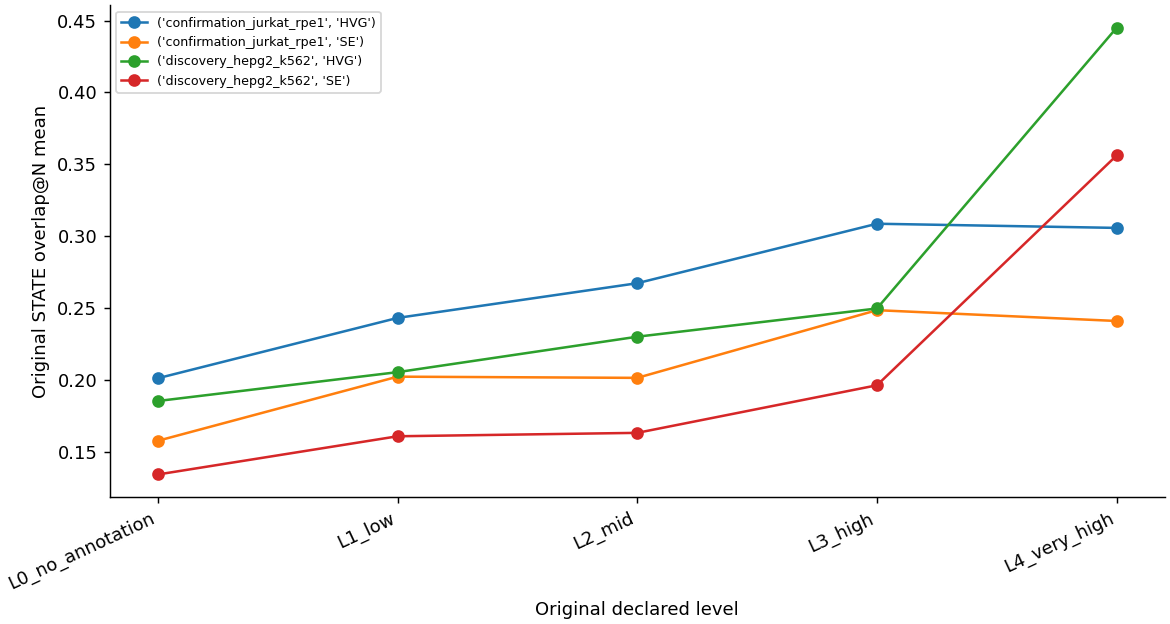

Curves are recalculated means under the original grouping rule. No new confidence bands have been added.


In [5]:
curve=ns.compare_curve('spc_state_replogle_symbol_family_support_control.csv', initial=False)
ns.show_curve(curve)

## Original agent decision and supporting diagnostics

The following records preserve the agent’s actual determination, including rejected candidates and controls. Their historical status labels are shown as recorded.

In [6]:
screen=pd.read_csv(rp.CONTINUED/'artifacts/replogle_refined_axis_screen.csv')
display(screen[screen.feature=='symbol_family_candidate_train_count'])
ns.display_json(rp.CONTINUED/'artifacts/replogle_refined_axis_screen.json')

,axis_id,feature,status,discovery_pass,confirmation_pass,all_context_pass,score_confirmation_mean_high_minus_low,n_confirmation_representations,discovery_high_minus_low_mean,confirmation_high_minus_low_mean
4,STATE_REPLOGLE_SYMBOL_FAMILY_SUPPORT_CONTROL,symbol_family_candidate_train_count,tested,True,True,True,0.09401,2,0.240916,0.09401


```json
{
  "status": "completed",
  "screen": [
    {
      "axis_id": "STATE_REPLOGLE_REACTOME_PATHWAY_LOG_TRAIN_SUPPORT_V2",
      "feature": "reactome_pathway_train_support_log_mean",
      "status": "tested",
      "discovery_pass": true,
      "confirmation_pass": true,
      "all_context_pass": true,
      "score_confirmation_mean_high_minus_low": 0.11856279265461289,
      "n_confirmation_representations": 2,
      "discovery_high_minus_low_mean": 0.14784159123409074,
      "confirmation_high_minus_low_mean": 0.11856279265461289
    },
    {
      "axis_id": "STATE_REPLOGLE_REACTOME_PATHWAY_MEAN_TRAIN_SUPPORT_V2",
      "feature": "reactome_pathway_train_support_mean",
      "status": "tested",
      "discovery_pass": true,
      "confirmation_pass": true,
      "all_context_pass": true,
      "score_confirmation_mean_high_minus_low": 0.09200171768458447,
      "n_confirmation_representations": 2,
      "discovery_high_minus_low_mean": 0.11962718436640678,
      "confirmation_high_minus_low_mean": 0.09200171768458447
    },
    {
      "axis_id": "STATE_REPLOGLE_REACTOME_PATHWAY_MIN_TRAIN_SUPPORT_V2",
      "feature": "reactome_pathway_train_support_min",
      "status": "tested",
      "discovery_pass": true,
      "confirmation_pass": true,
      "all_context_pass": true,
      "score_confirmation_mean_high_minus_low": 0.11597832610923275,
      "n_confirmation_representations": 2,
      "discovery_high_minus_low_mean": 0.16373107995045005,
      "confirmation_high_minus_low_mean": 0.11597832610923275
    },
    {
      "axis_id": "STATE_REPLOGLE_HGNC_GROUP_LOG_TRAIN_SUPPORT_V2",
      "feature": "hgnc_group_train_support_log_mean",
      "status": "tested",
      "discovery_pass": true,
      "confirmation_pass": true,
      "all_context_pass": true,
      "score_confirmation_mean_high_minus_low": 0.10463953924354054,
      "n_confirmation_representations": 2,
      "discovery_high_minus_low_mean": 0.1625647755386408,
      "confirmation_high_minus_low_mean": 0.10463953924354054
    },
    {
      "axis_id": "STATE_REPLOGLE_SYMBOL_FAMILY_SUPPORT_CONTROL",
      "feature": "symbol_family_candidate_train_count",
      "status": "tested",
      "discovery_pass": true,
      "confirmation_pass": true,
      "all_context_pass": true,
      "score_confirmation_mean_high_minus_low": 0.09400951562164811,
      "n_confirmation_representations": 2,
      "discovery_high_minus_low_mean": 0.2409159769571028,
      "confirmation_high_minus_low_mean": 0.09400951562164811
    }
  ],
  "best_axis": {
    "axis_id": "STATE_REPLOGLE_REACTOME_PATHWAY_LOG_TRAIN_SUPPORT_V2",
    "feature": "reactome_pathway_train_support_log_mean",
    "description": "Mean log(1 + same-context training genes sharing each Reactome pathway of the target gene)",
    "decision": "valid_current_pool_confirmed",
    "caveat": "Confirmed on held-out Replogle contexts using official scored rows; fresh raw-data confirmation would further strengthen the claim.",
    "freeze": {
      "axis_id": "STATE_REPLOGLE_REACTOME_PATHWAY_LOG_TRAIN_SUPPORT_V2",
      "status": "frozen_from_discovery_contexts_before_heldout_context_confirmation",
      "feature": "reactome_pathway_train_support_log_mean",
      "description": "Mean log(1 + same-context training genes sharing each Reactome pathway of the target gene)",
      "unit": "Replogle few-shot gene perturbation in target cell context and representation",
      "similarity_direction": "higher support means closer to same-context training biology",
      "performance_direction": "STATE performance should degrade as support decreases",
      "discovery_contexts": [
        "hepg2",
        "k562"
      ],
      "confirmation_contexts": [
        "jurkat",
        "rpe1"
      ],
      "cutpoints_from_discovery": [
        2.3128842769830324,
        2.748013858950496,
        3.2382440667788206
      ],
      "level_rule": "L0 if no annotation; otherwise discovery quantile support bins from low to high",
      "target_metric": "overlap_at_N",
      "artifacts": [
        "/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_state_replogle_reactome_pathway_log_train_support_v2.csv",
        "/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_state_replogle_reactome_pathway_log_train_support_v2_trends.csv",
        "/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/spectra_ready_dataset/state_replogle_reactome_pathway_log_train_support_v2_examples.csv"
      ]
    },
    "levels_artifact": "/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_replogle_best_refined_axis.csv",
    "trends_artifact": "/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_replogle_best_refined_axis_trends.csv",
    "context_trends_artifact": "/ewsc/yektefai/spectra_runs/state_generalizability_continued_20260603/artifacts/spc_replogle_best_refined_axis_context_trends.csv"
  }
}
```

All source files, downloaded inputs and historical outputs are checksummed in `original_manifest.json`. The full preliminary candidate screening and download inventory are retained in notebook `00-original-downloads-and-axis-history.ipynb`.